# Stage 1 — POD reduced-order models, intrusive and data-driven

**Vamsi Gudipati**

I take one parametric transient heat-conduction problem (a Gaussian source at a variable position on a square plate, stepped with backward Euler), compress its solutions with proper orthogonal decomposition (POD), and build two reduced-order models on the same 15 modes: an intrusive POD-Galerkin model that projects the solver's own operator, and a data-driven one that regresses the POD coefficients on the source position. Both are fast and accurate inside the parameter box they were built on, and both fail outside it in different ways. I ran the notebook's five closing experiments, repeated every random draw with three seeds, and added an animation of the full and the reduced model stepping side by side. Stage 2 uses this POD backbone in a digital twin.

Portfolio page: https://vamsigudipati.github.io/rom-ladle-digital-twin.html

In [1]:
# Where this notebook writes its outputs (paths relative to notebooks/)
from pathlib import Path
STAGE = "01_pod_rom_intrusive_and_data_driven"
RESULTS_DIR = Path("../results") / STAGE
EXERCISES_DIR = RESULTS_DIR / "exercises"
MODELS_DIR = Path("../models") / STAGE
ANIM_DIR = Path("../animations")
ANIM_PREFIX = "01_"
for _d in (RESULTS_DIR, EXERCISES_DIR, MODELS_DIR, ANIM_DIR):
    _d.mkdir(parents=True, exist_ok=True)

# Reduced-Order Models: POD-Galerkin and Data-Driven

We take one parametric transient-conduction problem and build two kinds of reduced-order model (ROM) for it, then break both on purpose. A ROM answers the same question as your full solver, for many different inputs, at a fraction of the cost. The catch is that it only works on the family of solutions it was built from. Watching *where* it stops working is the point of this stage, and it sets up Stage 2.

The problem is a Gaussian heat source sitting at a variable location $\mu=(x_0,y_0)$ in a square plate, stepped in time with backward Euler. The full-order model (FOM) is the honest solver we trust. Everything downstream tries to replace it.

Two ROM flavors, built and compared honestly:

- **Intrusive (POD-Galerkin):** project the actual time-stepping operator onto a handful of POD modes. Fast and physics-faithful, but it needs the solver's internals.
- **Non-intrusive (data-driven):** learn a map from the parameter $\mu$ straight to the POD coefficients, from input/output data alone. Solver-agnostic, but only as good as its data.

| Part | What | Section |
|---|---|---|
| Reference | the full-order transient solver (FOM) | 1 |
| Compression | snapshots, SVD, POD basis, error vs rank | 2 |
| Intrusive ROM | POD-Galerkin projection of the solver | 3 |
| Non-intrusive ROM | regress $\mu \to$ POD coefficients | 4 |
| Failure | push both ROMs off their training manifold | 5 |
| Close | takeaways and an experiment to run | 6 |

Everything runs on a Colab CPU in well under a minute. Only NumPy, SciPy, and Matplotlib are needed. Here we stay concrete and build.

In [2]:
# Device report: this notebook uses NumPy/SciPy/scikit-learn only (CPU); listed for completeness
import platform, os
print("Python", platform.python_version(), "| no GPU framework imported by this notebook")

Python 3.12.14 | no GPU framework imported by this notebook


### Running this notebook

Run top to bottom. A few cells call the full solver many times to build data (the POD sweep in Section 2, the timing and training sets in Sections 3 and 4). Each is flagged in a comment. Everything finishes in well under a minute on a CPU, and nothing needs a GPU or a package install.

In [3]:
# Imports, reproducibility, and plotting defaults.
import time
import numpy as np
import scipy.sparse as sp
from scipy.sparse.linalg import splu
import matplotlib.pyplot as plt

np.random.seed(0)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10,
                     "axes.grid": True, "grid.alpha": 0.25})

In [4]:
# Wong colorblind-safe palette.
CB = ["#0072B2", "#E69F00", "#009E73", "#D55E00", "#CC79A7", "#56B4E9", "#F0E442"]

In [5]:
# Heat-map of a scalar field on the unit square.
def heat(ax, F, title="", cmap="inferno", vmin=None, vmax=None, xlabel="x", ylabel="y"):
    im = ax.imshow(F, extent=[0, 1, 0, 1], origin="lower", aspect="auto",
                   cmap=cmap, vmin=vmin, vmax=vmax)
    ax.set_title(title); ax.set_xlabel(xlabel); ax.set_ylabel(ylabel); ax.grid(False)
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    return im

In [6]:
# Three panels: reference | prediction | |error|.
def panels3(ref, pred, main="", cmap="inferno"):
    err = np.abs(pred - ref)
    fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
    vmin = float(min(ref.min(), pred.min()))
    vmax = float(max(ref.max(), pred.max()))

    heat(ax[0], ref,  "reference (FOM)", cmap, vmin, vmax)
    heat(ax[1], pred, "ROM prediction",  cmap, vmin, vmax)
    heat(ax[2], err,  f"|error|  (max {err.max():.3g})", "viridis")

    fig.suptitle(main); plt.tight_layout(); plt.show()

print("ready | numpy", np.__version__)

ready | numpy 2.5.3


## Section 1. The physics and a full-order solver we trust

Transient heat conduction on the unit square with a fixed-in-time source:

$$\frac{\partial T}{\partial t}=\nabla^2 T + f_\mu(x,y),\qquad (x,y)\in[0,1]^2,\; T=0 \text{ on the boundary}.$$

The source is a Gaussian bump whose center is the parameter we vary:

$$f_\mu(x,y)=200\,\exp\!\left(-\frac{(x-x_0)^2+(y-y_0)^2}{2\,w^2}\right),\qquad \mu=(x_0,y_0),\; w=0.09.$$

We discretize space with the standard 5-point Laplacian and step time with **backward Euler**, which is unconditionally stable:

$$(I-\Delta t\,L)\,T^{n+1}=T^n+\Delta t\,f_\mu.$$

The matrix $A=I-\Delta t\,L$ never changes, so we factorize it once and reuse the factors for every step and every $\mu$. That single factorization is what makes the FOM fast enough to generate training data, and slow enough (per query, times many queries) to be worth replacing.

`build_problem(n_grid)` packages the whole solver for one grid resolution: coordinates, the Laplacian, the prefactored step matrix, the source, and `solve_fom`. Writing it as a factory lets us run the *same* code on a small grid first (everything printable) and on the full grid after.

In [7]:
class Problem:
    """Container for one full-order transient-conduction solver."""
    pass

In [8]:
def build_problem(n_grid, dt=2e-4, n_steps=300):
    p = Problem()
    p.n_grid = n_grid
    p.h      = 1.0 / (n_grid - 1)        # uniform spacing, boundaries included
    p.n_int  = n_grid - 2                # interior points per side
    p.n_dof  = p.n_int * p.n_int         # full-order degrees of freedom

    xs = np.linspace(0, 1, n_grid)
    Xg, Yg = np.meshgrid(xs, xs, indexing="ij")
    p.x_int = Xg[1:-1, 1:-1].ravel()     # interior-node coordinates
    p.y_int = Yg[1:-1, 1:-1].ravel()

    # 2D Laplacian as a Kronecker sum of two 1D second-difference operators.
    eye = sp.identity(p.n_int)
    d2  = sp.diags([1.0, -2.0, 1.0], [-1, 0, 1], shape=(p.n_int, p.n_int)) / p.h**2
    p.laplacian = (sp.kron(d2, eye) + sp.kron(eye, d2)).tocsc()

    # Backward-Euler step matrix, factorized once and reused.
    p.dt, p.n_steps = dt, n_steps
    p.system    = (sp.identity(p.n_dof) - dt * p.laplacian).tocsc()
    p.system_lu = splu(p.system)

    # Gaussian source centered at mu = (x0, y0).
    def source_term(mu, width=0.09):
        x0, y0 = mu
        return 200.0 * np.exp(-((p.x_int - x0)**2 + (p.y_int - y0)**2) / (2 * width**2))
    p.source_term = source_term

    # Step the FOM to the final field, optionally keeping snapshots for POD.
    def solve_fom(mu, width=0.09, store_snapshots=False, every=10):
        T = np.zeros(p.n_dof)
        forcing = dt * source_term(mu, width)
        snaps = []
        for step in range(n_steps):
            T = p.system_lu.solve(T + forcing)      # reuse the LU factors
            if store_snapshots and step % every == 0:
                snaps.append(T.copy())
        return (T, snaps) if store_snapshots else T
    p.solve_fom = solve_fom

    return p

In [9]:
# Reshape an interior-DOF vector to a plottable (y, x) image.
def as_grid(p, vec):
    return vec.reshape(p.n_int, p.n_int).T

In [10]:
# Build the full-resolution problem and report its size.
p = build_problem(50)
print(f"grid {p.n_grid} x {p.n_grid}  ->  interior {p.n_int} x {p.n_int}  =  {p.n_dof} DOF")
print(f"step matrix A = I - dt*L : {p.system.shape}, {p.system.nnz} nonzeros (sparse)")

grid 50 x 50  ->  interior 48 x 48  =  2304 DOF
step matrix A = I - dt*L : (2304, 2304), 11328 nonzeros (sparse)


In [11]:
# One solve at a fixed source location.
mu0 = (0.45, 0.6)
src   = p.source_term(mu0)
field = p.solve_fom(mu0)

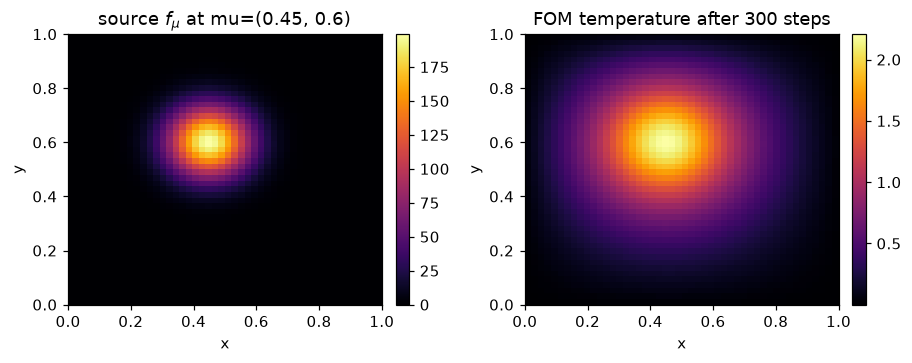

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(8.5, 3.4))
heat(ax[0], as_grid(p, src),   f"source $f_\\mu$ at mu={mu0}")
heat(ax[1], as_grid(p, field), f"FOM temperature after {p.n_steps} steps")
plt.tight_layout(); plt.show()

## Section 2. POD as compression

Before any ROM, ask a simpler question: how many numbers does one temperature field really need? Run the FOM at several source locations, stack the fields it passes through into a **snapshot matrix** $S$ (one field per column), and look at its singular value decomposition:

$$S = U\,\Sigma\,V^\top.$$

The left singular vectors in $U$ are the **POD modes**, ranked by how much of the snapshot energy they carry (the singular values in $\Sigma$). Keep the first $r$ columns, call them $\Phi$, and any snapshot is well approximated by a short coefficient vector:

$$T \approx \Phi\,a,\qquad a=\Phi^\top T \in \mathbb{R}^r.$$

$\Phi$ has orthonormal columns, so $\Phi^\top\Phi=I$. That fact does real work in Section 3. If the singular values fall off fast, a handful of modes reconstruct the field almost exactly, and $r \ll N_\text{dof}$. This section is compression only: no dynamics yet, and reconstruction uses the true field's own projection, which is the best a rank-$r$ basis can possibly do.

We do it on a coarse grid first, where every array is small enough to print, then rerun the same steps at full resolution.

In [13]:
# Coarse warm-up: small enough that every array is printable.
pc = build_problem(16)
warm_mus = np.array([[0.4, 0.4], [0.5, 0.6], [0.6, 0.45], [0.45, 0.55]])

# Collect transient snapshots from a few solves and take their SVD.
snaps = []
for mu in warm_mus:
    snaps += pc.solve_fom(mu, store_snapshots=True, every=15)[1]
S_coarse = np.column_stack(snaps)
U_c, s_c, _ = np.linalg.svd(S_coarse, full_matrices=False)

print(f"n_dof (coarse)     = {pc.n_dof}")
print(f"snapshot matrix S  = {S_coarse.shape}  (n_dof x n_snapshots)")
print(f"first 8 singular values = {np.round(s_c[:8], 2)}")

n_dof (coarse)     = 196
snapshot matrix S  = (196, 80)  (n_dof x n_snapshots)
first 8 singular values = [56.6  17.5  15.93  4.36  2.86  1.42  1.31  0.3 ]


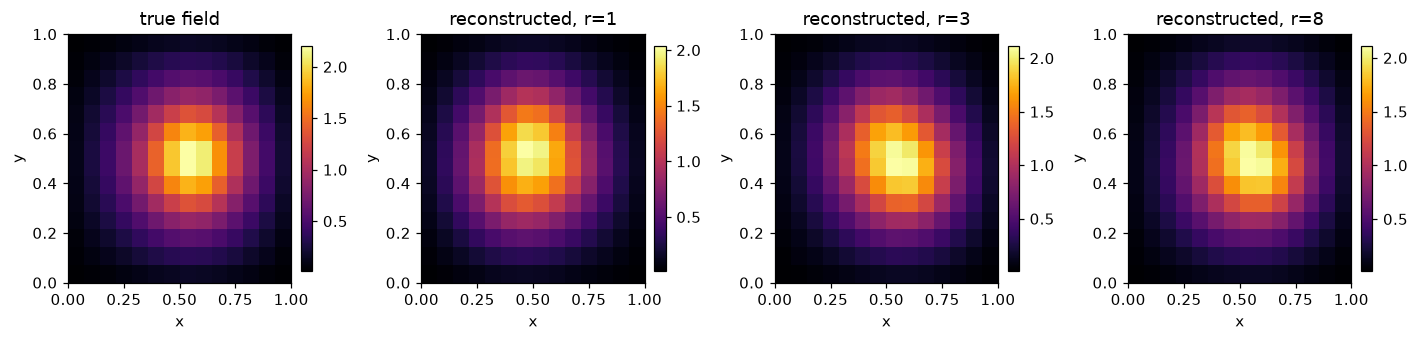

In [14]:
# Reconstruct one field with r = 1, 3, 8 modes.
target = pc.solve_fom((0.55, 0.5))
fig, ax = plt.subplots(1, 4, figsize=(13, 3.2))
heat(ax[0], as_grid(pc, target), "true field")
for k, r in enumerate([1, 3, 8], start=1):
    a = U_c[:, :r].T @ target
    heat(ax[k], as_grid(pc, U_c[:, :r] @ a), f"reconstructed, r={r}")
plt.tight_layout(); plt.show()

In [15]:
# The rank-8 coefficient vector: eight numbers standing in for a whole field.
a8 = U_c[:, :8].T @ target
print("coefficient vector a (r=8):", np.round(a8, 2))

coefficient vector a (r=8): [-10.15   0.55  -2.08  -0.23  -0.16  -0.05  -0.07  -0.28]


**Read-off.** The singular values drop by more than an order of magnitude within the first few modes, so one mode already captures the gross shape and three make it nearly right. The coefficient vector is eight numbers standing in for a whole field. That compression is the entire basis for what follows.

Now the full grid, with a proper parameter sweep for the snapshots.

In [16]:
# Full-grid POD: sweep source locations, collect transient snapshots, take the SVD.
# This runs 40 full solves, so it is the main data-building step (a few seconds).
rng = np.random.default_rng(0)
off_mus = rng.uniform(0.3, 0.7, size=(40, 2))        # training box for every ROM below

t0 = time.perf_counter()
snaps = []
for mu in off_mus:
    snaps += p.solve_fom(mu, store_snapshots=True, every=10)[1]
S = np.column_stack(snaps)
basis, sv, _ = np.linalg.svd(S, full_matrices=False)
offline_time = time.perf_counter() - t0
print(f"snapshot matrix S = {S.shape}   POD offline (solves + SVD) = {offline_time:.2f}s")

snapshot matrix S = (2304, 1200)   POD offline (solves + SVD) = 1.18s


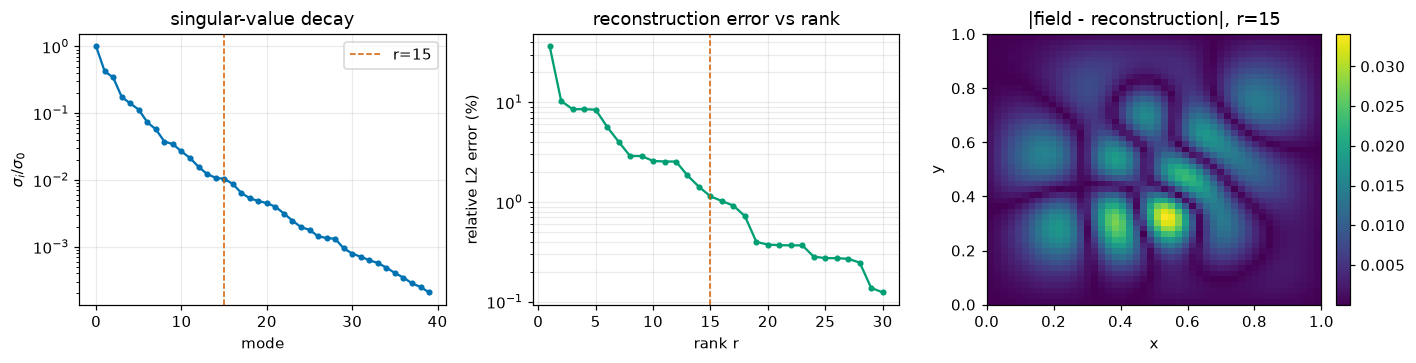

rank-15 reconstruction error on the held-out field = 1.14%


In [17]:
# Reconstruction error vs number of modes, on a held-out field.
test_field = p.solve_fom((0.52, 0.38))
ranks = np.arange(1, 31)
rec_err = [np.linalg.norm(test_field - basis[:, :r] @ (basis[:, :r].T @ test_field))
           / np.linalg.norm(test_field) for r in ranks]

fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))

# Singular-value decay.
ax[0].semilogy(sv[:40] / sv[0], "o-", ms=3, color=CB[0])
ax[0].axvline(15, color=CB[3], ls="--", lw=1, label="r=15")
ax[0].set_title("singular-value decay"); ax[0].set_xlabel("mode")
ax[0].set_ylabel(r"$\sigma_i/\sigma_0$"); ax[0].legend()

# Reconstruction error vs rank.
ax[1].semilogy(ranks, np.array(rec_err) * 100, "o-", ms=3, color=CB[2])
ax[1].axvline(15, color=CB[3], ls="--", lw=1)
ax[1].set_title("reconstruction error vs rank"); ax[1].set_xlabel("rank r")
ax[1].set_ylabel("relative L2 error (%)"); ax[1].grid(True, which="both", alpha=0.25)

# Error field at r = 15.
r_show = 15
rec = basis[:, :r_show] @ (basis[:, :r_show].T @ test_field)
heat(ax[2], as_grid(p, np.abs(test_field - rec)),
     f"|field - reconstruction|, r={r_show}", cmap="viridis")
plt.tight_layout(); plt.show()

print(f"rank-15 reconstruction error on the held-out field = {rec_err[14]*100:.2f}%")

## Section 3. Intrusive ROM: POD-Galerkin

Compression tells us a rank-$r$ subspace holds the answer. The intrusive ROM steps the physics *inside that subspace* instead of the full one. Substitute the ansatz $T\approx\Phi a$ into the backward-Euler step $A\,T^{n+1}=T^n+\Delta t\,f$, with $A=I-\Delta t\,L$:

$$A\,\Phi\,a^{n+1} = \Phi\,a^{n} + \Delta t\,f.$$

That is $N_\text{dof}$ equations for only $r$ unknowns. It is overdetermined, so we cannot satisfy all of them. **Galerkin projection** picks the $a^{n+1}$ that makes the leftover residual orthogonal to the subspace we are working in, the span of $\Phi$. Enforce orthogonality by multiplying through by $\Phi^\top$:

$$\underbrace{\Phi^\top A\,\Phi}_{A_r\;(r\times r)}\,a^{n+1} = \underbrace{\Phi^\top\Phi}_{=\,I}\,a^{n} + \Delta t\,\Phi^\top f.$$

The $\Phi^\top\Phi=I$ term is where orthonormal POD modes pay off. What is left is a tiny $r\times r$ system:

$$A_r\,a^{n+1} = a^{n} + \Delta t\,\Phi^\top f,\qquad A_r=\Phi^\top A\,\Phi.$$

$A_r$ does not depend on $\mu$, so we form and invert it once (it is $r\times r$, trivial). Per query, we project the source down with $\Phi^\top f$, step the small system, and lift back with $\Phi a$. This is "intrusive" because building $A_r$ needs the operator $A$ itself, not just solver outputs.

In [18]:
# POD-Galerkin ROM. Returns (Phi, rom, A_r).
def build_rom(p, basis, rank):
    Phi   = basis[:, :rank]
    A_r   = Phi.T @ (p.system @ Phi)          # r x r reduced operator
    A_inv = np.linalg.inv(A_r)                # precompute once, reuse every step

    def rom(mu, width=0.09):
        a = np.zeros(rank)
        forcing = p.dt * (Phi.T @ p.source_term(mu, width))   # project source down
        for _ in range(p.n_steps):
            a = A_inv @ (a + forcing)                         # step in the subspace
        return Phi @ a                                        # lift back to full space
    return Phi, rom, A_r

In [19]:
# The reduced operator is a tiny dense matrix.
_, _, A_r_small = build_rom(p, basis, 4)
print("reduced operator A_r for r=4 (a full 4x4 matrix):")
print(np.round(A_r_small, 3))

# Build the working ROM at rank 15.
RANK = 15
Phi, rom, A_r = build_rom(p, basis, RANK)
print(f"\nusing r = {RANK}:  A_r is {A_r.shape}, replacing the {p.n_dof}-DOF solver")

reduced operator A_r for r=4 (a full 4x4 matrix):
[[ 1.005e+00  0.000e+00 -0.000e+00 -1.000e-03]
 [ 0.000e+00  1.012e+00 -0.000e+00 -0.000e+00]
 [-0.000e+00 -0.000e+00  1.012e+00  0.000e+00]
 [-1.000e-03 -0.000e+00  0.000e+00  1.021e+00]]

using r = 15:  A_r is (15, 15), replacing the 2304-DOF solver


In [20]:
# Accuracy on a fresh in-box test set, and the many-query speedup.
# This times 40 full solves against 40 ROM steps, so it runs the FOM 40 times.
test_mus = rng.uniform(0.32, 0.68, size=(40, 2))
fom_refs = [p.solve_fom(mu) for mu in test_mus]
err_int  = np.mean([np.linalg.norm(r - rom(mu)) / np.linalg.norm(r)
                    for r, mu in zip(fom_refs, test_mus)])

t = time.perf_counter(); [p.solve_fom(mu) for mu in test_mus]; fom_time = time.perf_counter() - t
t = time.perf_counter(); [rom(mu)        for mu in test_mus]; rom_time = time.perf_counter() - t
speedup = fom_time / rom_time

print(f"intrusive ROM mean relative L2 error (in-box) = {err_int*100:.2f}%")
print(f"{len(test_mus)} queries : FOM {fom_time*1e3:.0f} ms  vs  ROM {rom_time*1e3:.0f} ms  "
      f"->  speedup x{speedup:.0f}")

intrusive ROM mean relative L2 error (in-box) = 1.51%
40 queries : FOM 904 ms  vs  ROM 14 ms  ->  speedup x63


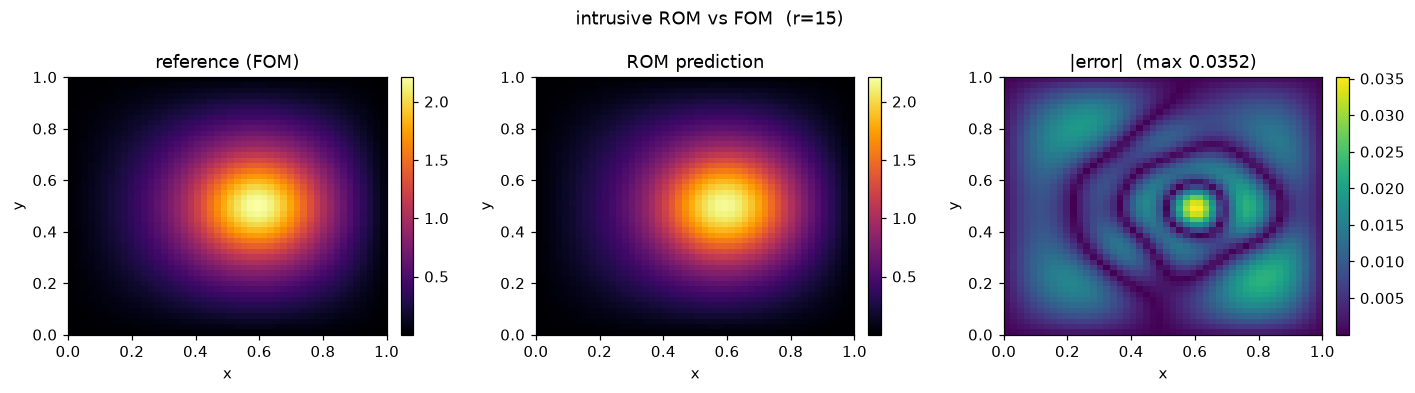

In [21]:
panels3(as_grid(p, fom_refs[0]), as_grid(p, rom(test_mus[0])),
        main=f"intrusive ROM vs FOM  (r={RANK})")

Accuracy is a dial you turn with the rank. More modes mean a bigger reduced system but a smaller error, until the error hits the noise floor set by the snapshot data. The many-query cost is the other half of the trade: the FOM pays a full sparse solve per step per query, the ROM pays a tiny dense step.

In [22]:
# Accuracy vs reduced dimension: rebuild the ROM at several ranks.
ranks = [3, 6, 10, 15, 25]
evr = []
for r in ranks:
    _, rom_r, _ = build_rom(p, basis, r)
    evr.append(np.mean([np.linalg.norm(ref - rom_r(mu)) / np.linalg.norm(ref)
                        for ref, mu in zip(fom_refs[:15], test_mus[:15])]))

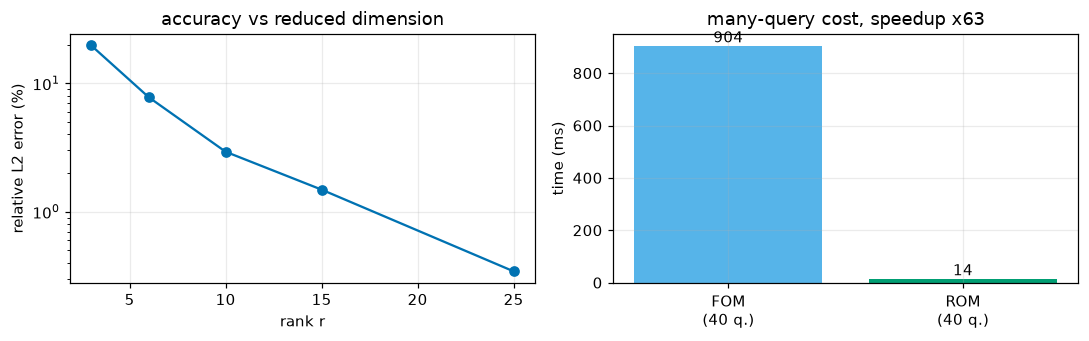

error vs rank: {3: '19.78%', 6: '7.80%', 10: '2.93%', 15: '1.49%', 25: '0.34%'}


In [23]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))

# Left: error shrinks as the reduced dimension grows.
ax[0].semilogy(ranks, np.array(evr) * 100, "o-", color=CB[0])
ax[0].set_xlabel("rank r"); ax[0].set_ylabel("relative L2 error (%)")
ax[0].set_title("accuracy vs reduced dimension")

# Right: many-query cost, FOM vs ROM.
ax[1].bar([f"FOM\n({len(test_mus)} q.)", f"ROM\n({len(test_mus)} q.)"],
          [fom_time * 1e3, rom_time * 1e3], color=[CB[5], CB[2]])
ax[1].set_ylabel("time (ms)"); ax[1].set_title(f"many-query cost, speedup x{speedup:.0f}")
for i, v in enumerate([fom_time * 1e3, rom_time * 1e3]):
    ax[1].text(i, v, f"{v:.0f}", ha="center", va="bottom")
plt.tight_layout(); plt.show()

print("error vs rank:", {r: f"{e*100:.2f}%" for r, e in zip(ranks, evr)})

## Section 4. Non-intrusive ROM: learn $\mu \to$ coefficients

The intrusive ROM needed the operator $A$. Often you do not have it: the solver is a black box, a licensed code, or an experiment. You still have pairs of (input $\mu$, output field). That is enough.

The idea is direct. Project every solved field onto the same POD basis to get its coefficient vector $a(\mu)=\Phi^\top T(\mu)$. Now you have a small supervised dataset, $\mu\in\mathbb{R}^2$ in, $a\in\mathbb{R}^r$ out, and you fit a regression to it. At query time you evaluate the regression to get $\hat a$, then lift with $\Phi\hat a$. No operator, no time stepping.

We use polynomial features of $\mu$ up to degree 4 with ridge regression, solved in a couple of lines of NumPy. It is transparent: the whole model is a small weight matrix. Radial basis functions or a small neural net (POD-NN) are the usual upgrades, and they would sharpen the numbers, but the polynomial makes the failure in Section 5 impossible to miss.

In [24]:
# Monomials of (x0, y0) up to `degree`, centered for conditioning.
def poly_features(M, degree=4, center=0.5):
    x, y = M[:, 0] - center, M[:, 1] - center
    cols = [(x**(d - i)) * (y**i) for d in range(degree + 1) for i in range(d + 1)]
    return np.column_stack(cols)

In [25]:
# Ridge regression, returning the weight matrix (n_features x r).
def fit_ridge(F, A, lam=1e-4):
    G = F.T @ F + lam * np.eye(F.shape[1])
    return np.linalg.solve(G, F.T @ A)

In [26]:
# Training data: reuse the offline mus, add more, project final fields onto Phi.
# This solves 100 fields, so it is the other main data-building step (a few seconds).
ni_mus    = np.vstack([off_mus, rng.uniform(0.3, 0.7, size=(60, 2))])
ni_fields = np.column_stack([p.solve_fom(mu) for mu in ni_mus])   # n_dof x n
A_coef    = (Phi.T @ ni_fields).T                                 # n x r  (targets)

F = poly_features(ni_mus, degree=4)
W = fit_ridge(F, A_coef)
print(f"training fields = {ni_fields.shape}   features F = {F.shape}   weights W = {W.shape}")

# The non-intrusive ROM: features of mu, times the weights, lifted by Phi.
def rom_ni(mu):
    a = poly_features(np.array([mu]), degree=4) @ W
    return Phi @ a.ravel()

err_ni = np.mean([np.linalg.norm(r - rom_ni(mu)) / np.linalg.norm(r)
                  for r, mu in zip(fom_refs, test_mus)])
print(f"\nin-box mean relative L2:  intrusive {err_int*100:.2f}%   "
      f"non-intrusive {err_ni*100:.2f}%")

training fields = (2304, 100)   features F = (100, 15)   weights W = (15, 15)

in-box mean relative L2:  intrusive 1.51%   non-intrusive 4.57%


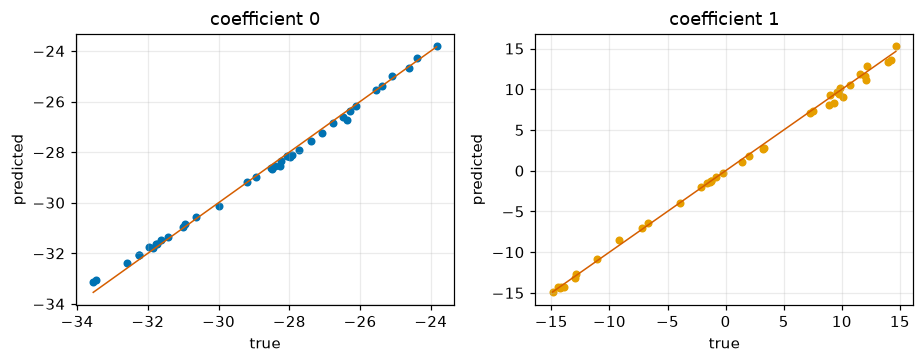

In [27]:
# How well does the regression fit the first two coefficients across the test set?
a_true = np.array([Phi.T @ r for r in fom_refs])
a_pred = np.array([poly_features(np.array([mu]), degree=4) @ W for mu in test_mus]).squeeze()

fig, ax = plt.subplots(1, 2, figsize=(8.5, 3.4))
for k, axk in enumerate(ax):
    axk.scatter(a_true[:, k], a_pred[:, k], s=18, color=CB[k])
    lo, hi = a_true[:, k].min(), a_true[:, k].max()
    axk.plot([lo, hi], [lo, hi], color=CB[3], lw=1)
    axk.set_title(f"coefficient {k}"); axk.set_xlabel("true"); axk.set_ylabel("predicted")
plt.tight_layout(); plt.show()

**What changes, and what does not, between the two ROMs.**

| | Intrusive (POD-Galerkin) | Non-intrusive (regression) |
|---|---|---|
| Needs | the operator $A$ (solver internals) | only $(\mu, \text{field})$ pairs |
| Enforces | the discretized physics, in the subspace | a fitted input/output map |
| In-box accuracy | best (limited by the basis) | good, limited by the data and the fit |
| New inputs | only handles what is in $\mu$, physics does the rest | only handles what is in $\mu$, full stop |
| Fails when | the solution leaves the basis span | the solution leaves the span, or you vary anything not in $\mu$ |

Both share the same POD basis $\Phi$, so both inherit the same blind spot: a subspace built from one family of solutions. The next section makes that blind spot visible, and shows the two ROMs failing in different ways.

## Section 5. Push both ROMs to failure

A ROM is trustworthy on the manifold it was trained on and nowhere else. The training box was $\mu\in[0.3,0.7]^2$ with a fixed source width. We now leave it, two ways.

**Axis 1: parameter extrapolation.** Slide the source toward a corner, out of the box. The true solution stops being a combination of the training snapshots, so the POD span no longer holds it.

In [28]:
# Slide mu diagonally from the box center out past a corner, and record both errors.
ts   = np.linspace(0.0, 1.0, 15)
sweep_mus = np.array([(0.5 - 0.45 * t, 0.5 - 0.45 * t) for t in ts])
ei, en = [], []
for mu in sweep_mus:
    ref = p.solve_fom(mu)
    ei.append(np.linalg.norm(ref - rom(mu))    / np.linalg.norm(ref))
    en.append(np.linalg.norm(ref - rom_ni(mu)) / np.linalg.norm(ref))

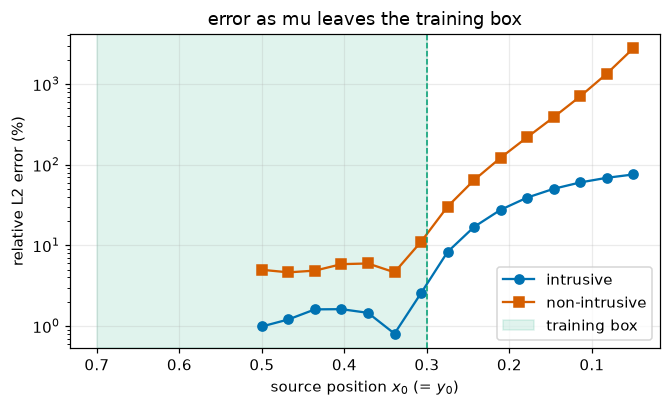

at mu=(0.5,0.5) in-box : intrusive 1.0%   non-intrusive 5.0%
at mu=(0.05,0.05) far  : intrusive 75.6%   non-intrusive 2764%


In [29]:
fig, ax = plt.subplots(figsize=(6.2, 3.8))
ax.semilogy(sweep_mus[:, 0], np.array(ei) * 100, "o-", color=CB[0], label="intrusive")
ax.semilogy(sweep_mus[:, 0], np.array(en) * 100, "s-", color=CB[3], label="non-intrusive")
ax.axvspan(0.3, 0.7, color=CB[2], alpha=0.12, label="training box")
ax.axvline(0.3, color=CB[2], ls="--", lw=1)
ax.invert_xaxis()                                   # travel is left-to-right, out of the box
ax.set_xlabel("source position $x_0$ (= $y_0$)")
ax.set_ylabel("relative L2 error (%)"); ax.set_title("error as mu leaves the training box")
ax.legend(); plt.tight_layout(); plt.show()

print(f"at mu=(0.5,0.5) in-box : intrusive {ei[0]*100:.1f}%   non-intrusive {en[0]*100:.1f}%")
print(f"at mu=(0.05,0.05) far  : intrusive {ei[-1]*100:.1f}%   non-intrusive {en[-1]*100:.0f}%")

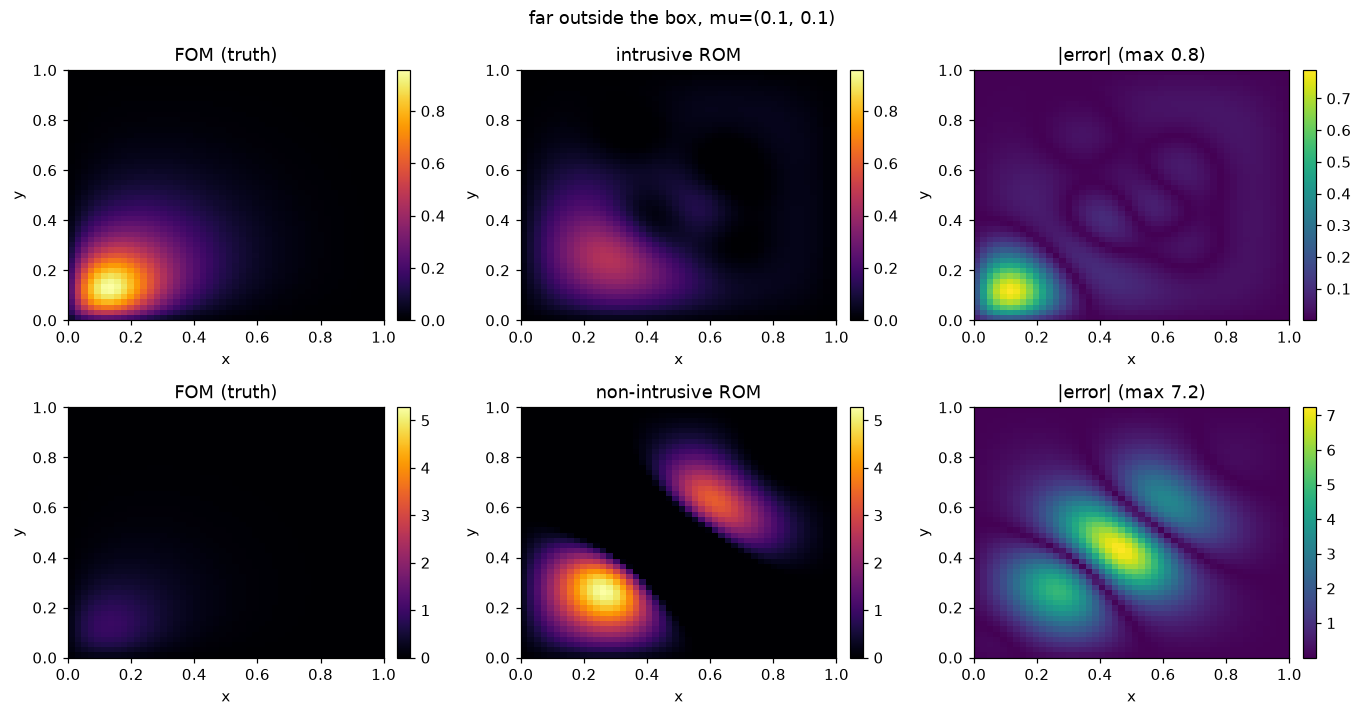

In [30]:
# Error fields at one far-corner mu: both ROMs, side by side.
mu_far = (0.1, 0.1)
ref = p.solve_fom(mu_far)
fig, ax = plt.subplots(2, 3, figsize=(12.5, 6.6))
for row, (name, pred) in enumerate([("intrusive", rom(mu_far)),
                                    ("non-intrusive", rom_ni(mu_far))]):
    e = np.abs(pred - ref)
    vmax = max(ref.max(), pred.max())
    heat(ax[row, 0], as_grid(p, ref),  "FOM (truth)", vmin=0, vmax=vmax)
    heat(ax[row, 1], as_grid(p, pred), f"{name} ROM",  vmin=0, vmax=vmax)
    heat(ax[row, 2], as_grid(p, e),    f"|error| (max {e.max():.1f})", cmap="viridis")
fig.suptitle(f"far outside the box, mu={mu_far}"); plt.tight_layout(); plt.show()

**Axis 2: an un-modeled variable.** Keep $\mu$ in the box, but double the source width to $w=0.18$, a shape neither ROM trained on. Here the two flavors part ways.

The intrusive ROM projects the *actual* wide source and steps the *actual* physics. As long as the wide-source solution still lives near the POD span (it does, the diffused field is another smooth central blob), it stays accurate. The non-intrusive ROM never saw width. Its only input is $\mu$, so it confidently returns the narrow-source answer for a wide-source question.

In [31]:
# Same center, but a source twice as wide, a shape neither ROM trained on.
mu_c = (0.5, 0.5)
ref_wide  = p.solve_fom(mu_c, width=0.18)          # truth, wide source
pred_int  = rom(mu_c, width=0.18)                  # intrusive sees the wide source
pred_ni   = rom_ni(mu_c)                            # non-intrusive only knows mu

err_int_w = np.linalg.norm(ref_wide - pred_int) / np.linalg.norm(ref_wide)
err_ni_w  = np.linalg.norm(ref_wide - pred_ni)  / np.linalg.norm(ref_wide)

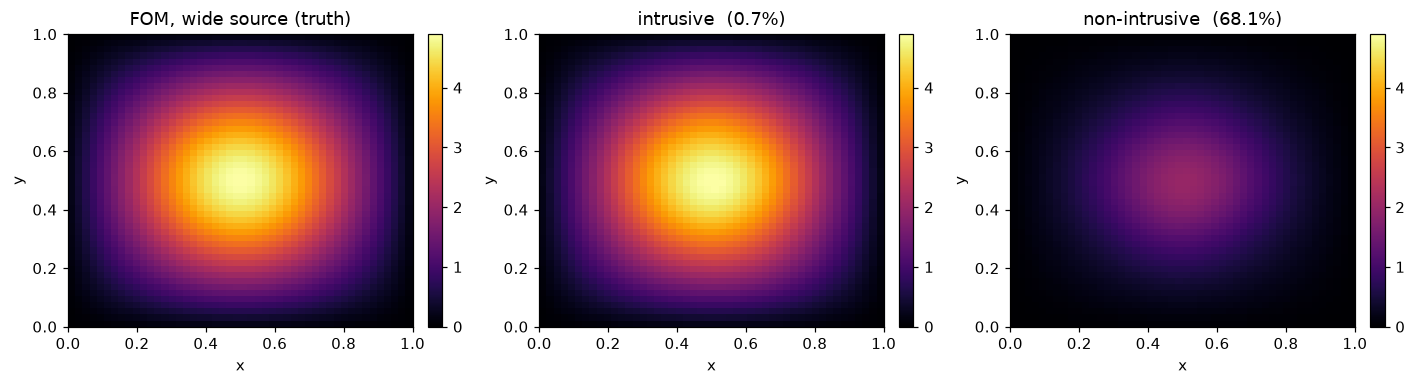

wide-source error : intrusive 0.7%   non-intrusive 68.1%


In [32]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
vmax = ref_wide.max()
heat(ax[0], as_grid(p, ref_wide), "FOM, wide source (truth)", vmin=0, vmax=vmax)
heat(ax[1], as_grid(p, pred_int), f"intrusive  ({err_int_w*100:.1f}%)", vmin=0, vmax=vmax)
heat(ax[2], as_grid(p, pred_ni),  f"non-intrusive  ({err_ni_w*100:.1f}%)", vmin=0, vmax=vmax)
plt.tight_layout(); plt.show()

print(f"wide-source error : intrusive {err_int_w*100:.1f}%   non-intrusive {err_ni_w*100:.1f}%")

**Read-off.** Inside the box, both ROMs are cheap and accurate. Cross the boundary and the error climbs fast, the intrusive one steeply, the non-intrusive one off the top of the chart, because a degree-4 polynomial extrapolates to nonsense. Change a variable the model never encoded, and the physics-based ROM absorbs it while the data-driven one cannot.

Look at the error fields, though. They are not random. The mistake has a clear spatial pattern tied to where the source moved. A structured, repeatable error is a modeling opportunity: if you can predict the error, you can correct it. That is exactly the move in **Stage 2**, where we learn the ROM's residual and add it back, turning a fast-but-wrong model into a fast-and-corrected one.

## Takeaways

- **POD compresses a solution family to a few numbers.** The SVD of a snapshot matrix ranks directions by energy. When singular values decay fast, a rank-$r$ basis reconstructs any in-family field with tiny error, and $r$ is a handful, not thousands.
- **Intrusive POD-Galerkin steps the physics in the subspace.** Project the operator, $A_r=\Phi^\top A\Phi$, project the source, step a tiny $r\times r$ system, lift back. Orthonormal modes make $\Phi^\top\Phi=I$, which collapses the projection to that clean form. It is accurate and gives a large many-query speedup, but it needs the operator.
- **Non-intrusive regression only needs data.** Learn $\mu\to a$ from input/output pairs, no operator, no stepping. It is competitive inside the training range and works when the solver is a black box, but it is only as good as its data and its regressor.
- **Both live on the training manifold.** Move the parameter out of the box and both degrade, the intrusive one gracefully then badly, the polynomial one explosively. Change a variable outside $\mu$ and only the physics-faithful ROM survives it.
- **The failure is structured, and structure is learnable.** The error field has shape, not noise. Stage 2 models it.

## Experiment: change this and rerun

- Change `RANK` and watch the accuracy and speed trade move. Push it to 25 or 30 and see the error hit the snapshot noise floor.
- Widen the training box `off_mus` toward the corners and rerun the failure sweep. The knee moves with the box, which is the whole point.
- Swap the non-intrusive regressor for radial basis functions or a tiny MLP on the same `(mu, a)` data, and compare both the in-box accuracy and the extrapolation blow-up.
- Add the source width as a second parameter: sample `(x0, y0, w)`, feed all three to `poly_features` and the snapshots, and watch the non-intrusive ROM stop being blind to shape.
- Shrink `n_steps` or coarsen the grid in `build_problem` to trade FOM accuracy for offline speed, and see how the POD spectrum responds.

# Experiment solutions
I run the five experiments of the closing section with the notebook's own solver (`build_problem`, `p.solve_fom`), POD basis (`basis`, `sv`), ROM builders (`build_rom`, `poly_features`, `fit_ridge`) and test set (`test_mus`, `fom_refs`), and the corner sweep of Section 5 (`ts`, `sweep_mus`). Errors are mean relative $\ell_2$ errors against the full-order model (FOM). Everything is NumPy/SciPy on the CPU, as in the notebook; a few minutes in total.

In [33]:
import pandas as pd
from pathlib import Path
from scipy.interpolate import RBFInterpolator
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
ex_dir = EXERCISES_DIR; ex_dir.mkdir(exist_ok=True)
def ex_rel(ref, pred): return float(np.linalg.norm(ref - pred) / np.linalg.norm(ref))
ex_sweep_refs = [p.solve_fom(mu) for mu in sweep_mus]
def ex_knee(errs, thr=0.05):
    over = np.flatnonzero(np.asarray(errs) > thr); return float(ts[over[0]]) if len(over) else None

## Experiment 1 — rank
Intrusive ROM at ranks 15 (the notebook's), 25 and 30: error on the 40 test parameters and time for 40 queries.

In [34]:
ex1_rows = []
for r in (15, 25, 30):
    _, rom_r, _ = build_rom(p, basis, r)
    t0 = time.perf_counter(); preds = [rom_r(mu) for mu in test_mus]; t = time.perf_counter() - t0
    ex1_rows.append(dict(rank=r, mean_rel_error=np.mean([ex_rel(a, b) for a, b in zip(fom_refs, preds)]), rom_ms_per_query=1e3 * t / len(test_mus),
                         speedup_vs_fom=fom_time / t, sv_ratio=float(sv[r - 1] / sv[0])))
ex1 = pd.DataFrame(ex1_rows); ex1.to_csv(ex_dir / "exp1_rank.csv", index=False); print(ex1)
print("Result (Experiment 1): intrusive ROM error " + ", ".join(f"r={r.rank}: {100*r.mean_rel_error:.3f} % (x{r.speedup_vs_fom:.0f} faster)" for r in ex1.itertuples()))

   rank  mean_rel_error  rom_ms_per_query  speedup_vs_fom  sv_ratio
0    15        0.015096          0.317194       71.219891  0.010793
1    25        0.003437          0.367905       61.403054  0.001969
2    30        0.001819          0.334821       67.470422  0.000949
Result (Experiment 1): intrusive ROM error r=15: 1.510 % (x71 faster), r=25: 0.344 % (x61 faster), r=30: 0.182 % (x67 faster)


The error falls with the rank until it levels off at the floor set by the snapshot set (the singular values of the higher modes are tiny, column `sv_ratio`), while each query gets slightly more expensive; beyond about rank 25 extra modes buy almost nothing.

## Experiment 2 — widen the training box
The snapshot box widened from $[0.3, 0.7]^2$ to $[0.15, 0.85]^2$ (40 parameters, as in the notebook), I build a new basis and rank-15 intrusive and non-intrusive ROMs built from it, and the corner sweep of Section 5 rerun for both boxes. The "knee" is the sweep position $t$ at which the error first exceeds 5 %.

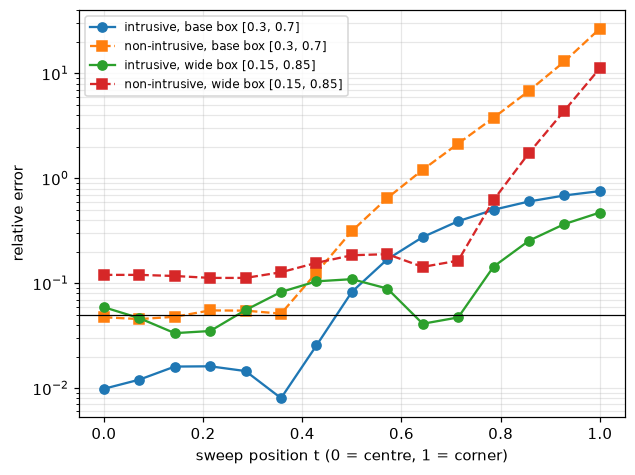

                     box  knee_intrusive  knee_nonintrusive  \
0    base box [0.3, 0.7]             0.5           0.214286   
1  wide box [0.15, 0.85]             0.0           0.000000   

   corner_err_intrusive  corner_err_nonintrusive  
0              0.756371                26.789786  
1              0.472465                11.218899  
Result (Experiment 2): 5 % knee (t) intrusive / non-intrusive: base box [0.3, 0.7]: 0.5 / 0.21428571428571427; wide box [0.15, 0.85]: 0.0 / 0.0


In [35]:
def ex_build_all(lo, hi, seed=0, rank=RANK):
    r_ = np.random.default_rng(seed); mus = r_.uniform(lo, hi, size=(40, 2)); sn = []
    for mu in mus: sn += p.solve_fom(mu, store_snapshots=True, every=10)[1]
    B, s_, _ = np.linalg.svd(np.column_stack(sn), full_matrices=False)
    Ph, rom_b, _ = build_rom(p, B, rank)
    ni = np.vstack([mus, r_.uniform(lo, hi, size=(60, 2))]); fl = np.column_stack([p.solve_fom(mu) for mu in ni])
    Wb = fit_ridge(poly_features(ni, degree=4), (Ph.T @ fl).T)
    return rom_b, (lambda mu: Ph @ (poly_features(np.array([mu]), degree=4) @ Wb).ravel()), B, s_, ni, fl, Ph
ex2_rows = []
for name, (lo, hi) in (("base box [0.3, 0.7]", (0.3, 0.7)), ("wide box [0.15, 0.85]", (0.15, 0.85))):
    rom_b, rom_nib, *_ = ex_build_all(lo, hi)
    ei_ = [ex_rel(r, rom_b(mu)) for r, mu in zip(ex_sweep_refs, sweep_mus)]; en_ = [ex_rel(r, rom_nib(mu)) for r, mu in zip(ex_sweep_refs, sweep_mus)]
    ex2_rows.append(dict(box=name, knee_intrusive=ex_knee(ei_), knee_nonintrusive=ex_knee(en_), corner_err_intrusive=ei_[-1], corner_err_nonintrusive=en_[-1]))
    plt.semilogy(ts, ei_, "o-", label=f"intrusive, {name}"); plt.semilogy(ts, en_, "s--", label=f"non-intrusive, {name}")
plt.axhline(0.05, color="k", lw=0.8); plt.xlabel("sweep position t (0 = centre, 1 = corner)"); plt.ylabel("relative error"); plt.legend(fontsize=8); plt.grid(alpha=0.3, which="both")
plt.savefig(ex_dir / "exp2_box_sweep.png", dpi=110); plt.show()
ex2 = pd.DataFrame(ex2_rows); ex2.to_csv(ex_dir / "exp2_box.csv", index=False); print(ex2)
print("Result (Experiment 2): 5 % knee (t) intrusive / non-intrusive: " + "; ".join(f"{r.box}: {r.knee_intrusive} / {r.knee_nonintrusive}" for r in ex2.itertuples()))

## Experiment 3 — other regressors for the non-intrusive ROM
The same $(\mu, a)$ data of Section 4 (`ni_mus`, coefficients on the notebook's rank-15 basis) fitted with radial basis functions (thin-plate spline, `scipy.interpolate.RBFInterpolator`) and with a small MLP (two hidden layers of 32, `sklearn`), against the notebook's degree-4 polynomial ridge fit: error on the 40 in-box test parameters and at the end of the corner sweep.

In [36]:
A_ni = (Phi.T @ ni_fields).T
ex3_models = {"polynomial ridge (base)": lambda M: poly_features(M, degree=4) @ W,
              "RBF thin-plate": RBFInterpolator(ni_mus, A_ni, kernel="thin_plate_spline"),
              "MLP 32-32": (lambda m: (lambda M: m.predict(M)))(make_pipeline(StandardScaler(), MLPRegressor(hidden_layer_sizes=(32, 32), max_iter=20000, random_state=0)).fit(ni_mus, A_ni))}
ex3_rows = []
for name, f in ex3_models.items():
    inbox = np.mean([ex_rel(r, Phi @ np.ravel(f(np.array([mu])))) for r, mu in zip(fom_refs, test_mus)])
    sweep = [ex_rel(r, Phi @ np.ravel(f(np.array([mu])))) for r, mu in zip(ex_sweep_refs, sweep_mus)]
    ex3_rows.append(dict(regressor=name, in_box_error=inbox, corner_error=sweep[-1], knee=ex_knee(sweep)))
ex3 = pd.DataFrame(ex3_rows); ex3.to_csv(ex_dir / "exp3_regressors.csv", index=False); print(ex3)
print("Result (Experiment 3): in-box / corner error: " + "; ".join(f"{r.regressor}: {100*r.in_box_error:.2f} % / {100*r.corner_error:.0f} %" for r in ex3.itertuples()))

                 regressor  in_box_error  corner_error      knee
0  polynomial ridge (base)      0.045678     27.637679  0.214286
1           RBF thin-plate      0.014172      7.598647  0.500000
2                MLP 32-32      0.046066     10.595560  0.000000
Result (Experiment 3): in-box / corner error: polynomial ridge (base): 4.57 % / 2764 %; RBF thin-plate: 1.42 % / 760 %; MLP 32-32: 4.61 % / 1060 %


## Experiment 4 — the source width as a third parameter
Snapshots and regression data sampled over $(x_0, y_0, w)$ with $w \in [0.06, 0.18]$ (the notebook fixes $w = 0.09$; Section 5 tests $w = 0.18$). A degree-3 polynomial in the three parameters replaces `poly_features`. Both base ROMs (blind to $w$) and the new ones are tested on 20 random in-box positions with $w = 0.18$ and with $w = 0.09$.

In [37]:
def ex_poly3(M, degree=3):
    x, y, w = M[:, 0] - 0.5, M[:, 1] - 0.5, (M[:, 2] - 0.12) / 0.06
    cols = [x**i * y**j * w**k for i in range(degree + 1) for j in range(degree + 1 - i) for k in range(degree + 1 - i - j)]
    return np.column_stack(cols)
r4 = np.random.default_rng(4)
mw = np.column_stack([r4.uniform(0.3, 0.7, (60, 2)), r4.uniform(0.06, 0.18, 60)]); sn = []
for m3 in mw[:40]: sn += p.solve_fom(m3[:2], width=m3[2], store_snapshots=True, every=10)[1]
B3, _, _ = np.linalg.svd(np.column_stack(sn), full_matrices=False); Ph3 = B3[:, :RANK]
fl3 = np.column_stack([p.solve_fom(m3[:2], width=m3[2]) for m3 in mw]); W3 = fit_ridge(ex_poly3(mw), (Ph3.T @ fl3).T)
_, rom3, _ = build_rom(p, B3, RANK)
ex4_rows = []
for wtest in (0.09, 0.18):
    tm = np.column_stack([r4.uniform(0.32, 0.68, (20, 2)), np.full(20, wtest)])
    refs = [p.solve_fom(m3[:2], width=wtest) for m3 in tm]
    ex4_rows.append(dict(test_width=wtest,
        base_intrusive=np.mean([ex_rel(r, rom(m3[:2], width=wtest)) for r, m3 in zip(refs, tm)]),
        base_nonintrusive=np.mean([ex_rel(r, rom_ni(m3[:2])) for r, m3 in zip(refs, tm)]),
        width_aware_intrusive=np.mean([ex_rel(r, rom3(m3[:2], width=wtest)) for r, m3 in zip(refs, tm)]),
        width_aware_nonintrusive=np.mean([ex_rel(r, Ph3 @ (ex_poly3(m3[None]) @ W3).ravel()) for r, m3 in zip(refs, tm)])))
ex4 = pd.DataFrame(ex4_rows); ex4.to_csv(ex_dir / "exp4_width_parameter.csv", index=False); print(ex4)
r_ = ex4[ex4.test_width == 0.18].iloc[0]
print(f"Result (Experiment 4): at w = 0.18 the base non-intrusive ROM errs by {100*r_.base_nonintrusive:.1f} %, the width-aware one by {100*r_.width_aware_nonintrusive:.2f} % "
      f"(intrusive: base basis {100*r_.base_intrusive:.2f} %, width-aware basis {100*r_.width_aware_intrusive:.2f} %)")

   test_width  base_intrusive  base_nonintrusive  width_aware_intrusive  \
0        0.09        0.014269           0.043011               0.019956   
1        0.18        0.029431           0.672850               0.008121   

   width_aware_nonintrusive  
0                  0.062180  
1                  0.024364  
Result (Experiment 4): at w = 0.18 the base non-intrusive ROM errs by 67.3 %, the width-aware one by 2.44 % (intrusive: base basis 2.94 %, width-aware basis 0.81 %)


## Experiment 5 — coarser grid and fewer time steps
The FOM rebuilt on a 30-point grid (50 in the notebook) and with 150 time steps (300 in the notebook; with $\Delta t$ unchanged this stops the transient earlier), the same 40 snapshot parameters; offline time and the decay of the POD singular values.

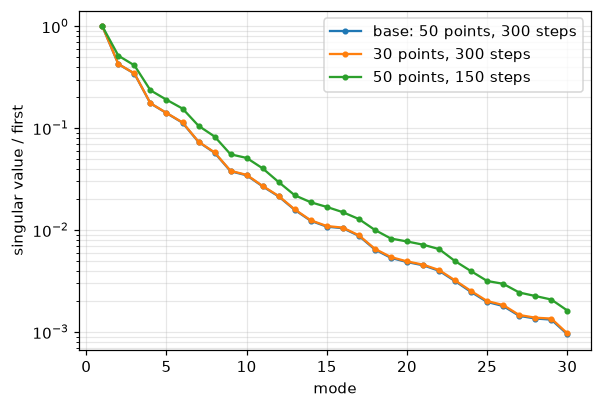

                        setup  n_dof  offline_s  modes_to_1e-3  modes_to_1e-5
0  base: 50 points, 300 steps   2304       1.23             30             64
1        30 points, 300 steps    784       0.35             30             64
2        50 points, 150 steps   2304       0.53             34             70
Result (Experiment 5): offline time / modes to reach 1e-3 of the first singular value: base: 50 points, 300 steps: 1.23 s / 30; 30 points, 300 steps: 0.35 s / 30; 50 points, 150 steps: 0.53 s / 34


In [38]:
ex5_rows = []; plt.figure(figsize=(6, 4))
for label, ng, nst in (("base: 50 points, 300 steps", 50, 300), ("30 points, 300 steps", 30, 300), ("50 points, 150 steps", 50, 150)):
    pp = build_problem(ng, n_steps=nst); t0 = time.perf_counter(); sn = []
    for mu in off_mus: sn += pp.solve_fom(mu, store_snapshots=True, every=10)[1]
    _, s5, _ = np.linalg.svd(np.column_stack(sn), full_matrices=False); t = time.perf_counter() - t0
    s5n = s5 / s5[0]; plt.semilogy(np.arange(1, 31), s5n[:30], "o-", ms=3, label=label)
    ex5_rows.append({"setup": label, "n_dof": pp.n_dof, "offline_s": round(t, 2), "modes_to_1e-3": int(np.argmax(s5n < 1e-3)) + 1, "modes_to_1e-5": int(np.argmax(s5n < 1e-5)) + 1})
plt.xlabel("mode"); plt.ylabel("singular value / first"); plt.legend(); plt.grid(alpha=0.3, which="both"); plt.savefig(ex_dir / "exp5_spectrum.png", dpi=110); plt.show()
ex5 = pd.DataFrame(ex5_rows); ex5.to_csv(ex_dir / "exp5_grid_steps.csv", index=False); print(ex5)
print("Result (Experiment 5): offline time / modes to reach 1e-3 of the first singular value: " + "; ".join(f"{r.setup}: {r.offline_s} s / {r._4}" for r in ex5.itertuples()))

## Summary of the experiments
The numbers are those printed in the `Result` lines above; the tables and figures are in the exercises results folder.

# Three-seed repeats
The notebook draws its 40 snapshot parameters, its 40 test parameters and its 60 extra regression parameters from one generator, `default_rng(0)`, in that order (Sections 2, 3 and 4). `ex_main_numbers(seed)` repeats the whole chain with `default_rng(seed)` in the same order, so seed 0 reproduces the notebook's own numbers and seeds 1 and 2 are two other draws of the training and test parameters: POD basis, rank-15 intrusive ROM, degree-4 ridge ROM, in-box errors, the corner sweep of Section 5 and the wide source. I repeat Experiments 2 to 4 the same way: Experiment 2 with `ex_build_all(..., seed)`, Experiment 3 with the MLP's `random_state` (the RBF and ridge fits are deterministic), Experiment 4 with `default_rng(4 + seed)` (seed 0 is the experiment's own `default_rng(4)`). Experiments 1 and 5 contain no random draw. The `seeds_*.csv` tables and `seeds_summary.png` go to the exercises results folder.

In [39]:
SEEDS = (0, 1, 2)
def ex_main_numbers(seed):
    r_ = np.random.default_rng(seed)
    offm = r_.uniform(0.3, 0.7, size=(40, 2)); sn = []
    for mu in offm: sn += p.solve_fom(mu, store_snapshots=True, every=10)[1]
    B, s_, _ = np.linalg.svd(np.column_stack(sn), full_matrices=False)
    Ph, rom_s, _ = build_rom(p, B, RANK)
    tm = r_.uniform(0.32, 0.68, size=(40, 2)); refs = [p.solve_fom(mu) for mu in tm]
    nim = np.vstack([offm, r_.uniform(0.3, 0.7, size=(60, 2))]); fl = np.column_stack([p.solve_fom(mu) for mu in nim])
    Ws = fit_ridge(poly_features(nim, degree=4), (Ph.T @ fl).T)
    rni = lambda mu: Ph @ (poly_features(np.array([mu]), degree=4) @ Ws).ravel()
    ei_ = [ex_rel(r, rom_s(mu)) for r, mu in zip(ex_sweep_refs, sweep_mus)]; en_ = [ex_rel(r, rni(mu)) for r, mu in zip(ex_sweep_refs, sweep_mus)]
    return dict(seed=seed,
                reconstruction_rank15=ex_rel(test_field, B[:, :15] @ (B[:, :15].T @ test_field)),
                intrusive_in_box=np.mean([ex_rel(r, rom_s(mu)) for r, mu in zip(refs, tm)]),
                nonintrusive_in_box=np.mean([ex_rel(r, rni(mu)) for r, mu in zip(refs, tm)]),
                intrusive_centre=ei_[0], nonintrusive_centre=en_[0], intrusive_corner=ei_[-1], nonintrusive_corner=en_[-1],
                knee_intrusive=ex_knee(ei_), knee_nonintrusive=ex_knee(en_),
                intrusive_wide_source=ex_rel(ref_wide, rom_s(mu_c, width=0.18)), nonintrusive_wide_source=ex_rel(ref_wide, rni(mu_c)))
seeds_main = pd.DataFrame([ex_main_numbers(s) for s in SEEDS]); seeds_main.to_csv(ex_dir / "seeds_main_runs.csv", index=False)
print(seeds_main.round(4).to_string())
print(f"check, seed 0 against the notebook: intrusive {seeds_main.intrusive_in_box[0]:.4f} (Section 3: {err_int:.4f}), non-intrusive {seeds_main.nonintrusive_in_box[0]:.4f} (Section 4: {err_ni:.4f})")

   seed  reconstruction_rank15  intrusive_in_box  nonintrusive_in_box  intrusive_centre  nonintrusive_centre  intrusive_corner  nonintrusive_corner  knee_intrusive  knee_nonintrusive  intrusive_wide_source  nonintrusive_wide_source
0     0                 0.0114            0.0151               0.0457            0.0099               0.0498            0.7564              27.6377          0.5000             0.2143                 0.0069                    0.6814
1     1                 0.0119            0.0140               0.0450            0.0120               0.0478            0.7487              24.9971          0.4286             0.1429                 0.0054                    0.6813
2     2                 0.0085            0.0136               0.0449            0.0094               0.0396            0.7723              28.2578          0.5000             0.3571                 0.0035                    0.6809
check, seed 0 against the notebook: intrusive 0.0151 (Section 3: 0.0151)

In [40]:
ex2_s, ex3_s, ex4_s = [], [], []
for seed in SEEDS:
    for name, (lo, hi) in (("box [0.3, 0.7]", (0.3, 0.7)), ("wide box [0.15, 0.85]", (0.15, 0.85))):
        rom_b, rom_nib, *_ = ex_build_all(lo, hi, seed=seed)
        ei_ = [ex_rel(r, rom_b(mu)) for r, mu in zip(ex_sweep_refs, sweep_mus)]; en_ = [ex_rel(r, rom_nib(mu)) for r, mu in zip(ex_sweep_refs, sweep_mus)]
        ex2_s.append(dict(seed=seed, box=name, knee_intrusive=ex_knee(ei_), knee_nonintrusive=ex_knee(en_), corner_err_intrusive=ei_[-1], corner_err_nonintrusive=en_[-1]))
    mlp = make_pipeline(StandardScaler(), MLPRegressor(hidden_layer_sizes=(32, 32), max_iter=20000, random_state=seed)).fit(ni_mus, A_ni)
    for name, f in (("polynomial ridge", lambda M: poly_features(M, degree=4) @ W), ("RBF thin-plate", ex3_models["RBF thin-plate"]), ("MLP 32-32", mlp.predict)):
        sweep = [ex_rel(r, Phi @ np.ravel(f(np.array([mu])))) for r, mu in zip(ex_sweep_refs, sweep_mus)]
        ex3_s.append(dict(seed=seed, regressor=name, in_box_error=np.mean([ex_rel(r, Phi @ np.ravel(f(np.array([mu])))) for r, mu in zip(fom_refs, test_mus)]),
                          corner_error=sweep[-1], knee=ex_knee(sweep)))
    r4s = np.random.default_rng(4 + seed)
    mws = np.column_stack([r4s.uniform(0.3, 0.7, (60, 2)), r4s.uniform(0.06, 0.18, 60)]); sn = []
    for m3 in mws[:40]: sn += p.solve_fom(m3[:2], width=m3[2], store_snapshots=True, every=10)[1]
    B3s, _, _ = np.linalg.svd(np.column_stack(sn), full_matrices=False); Ph3s = B3s[:, :RANK]
    fl3s = np.column_stack([p.solve_fom(m3[:2], width=m3[2]) for m3 in mws]); W3s = fit_ridge(ex_poly3(mws), (Ph3s.T @ fl3s).T)
    _, rom3s, _ = build_rom(p, B3s, RANK)
    for wtest in (0.09, 0.18):
        tm = np.column_stack([r4s.uniform(0.32, 0.68, (20, 2)), np.full(20, wtest)]); refs = [p.solve_fom(m3[:2], width=wtest) for m3 in tm]
        ex4_s.append(dict(seed=seed, test_width=wtest,
            base_intrusive=np.mean([ex_rel(r, rom(m3[:2], width=wtest)) for r, m3 in zip(refs, tm)]),
            base_nonintrusive=np.mean([ex_rel(r, rom_ni(m3[:2])) for r, m3 in zip(refs, tm)]),
            width_aware_intrusive=np.mean([ex_rel(r, rom3s(m3[:2], width=wtest)) for r, m3 in zip(refs, tm)]),
            width_aware_nonintrusive=np.mean([ex_rel(r, Ph3s @ (ex_poly3(m3[None]) @ W3s).ravel()) for r, m3 in zip(refs, tm)])))
    print(f"seed {seed} done", flush=True)
ex2_s, ex3_s, ex4_s = pd.DataFrame(ex2_s), pd.DataFrame(ex3_s), pd.DataFrame(ex4_s)
ex2_s.to_csv(ex_dir / "seeds_exp2_runs.csv", index=False); ex3_s.to_csv(ex_dir / "seeds_exp3_runs.csv", index=False); ex4_s.to_csv(ex_dir / "seeds_exp4_runs.csv", index=False)
print(ex2_s.round(4).to_string()); print(ex3_s.round(4).to_string()); print(ex4_s.round(4).to_string())

seed 0 done


seed 1 done


seed 2 done


   seed                    box  knee_intrusive  knee_nonintrusive  corner_err_intrusive  corner_err_nonintrusive
0     0         box [0.3, 0.7]          0.5000             0.2143                0.7564                  26.7898
1     0  wide box [0.15, 0.85]          0.0000             0.0000                0.4725                  11.2189
2     1         box [0.3, 0.7]          0.4286             0.3571                0.7487                  26.2755
3     1  wide box [0.15, 0.85]          0.0000             0.0000                0.7094                  16.6679
4     2         box [0.3, 0.7]          0.5000             0.1429                0.7723                  26.1637
5     2  wide box [0.15, 0.85]          0.0714             0.0000                0.5589                  12.3365
   seed         regressor  in_box_error  corner_error    knee
0     0  polynomial ridge        0.0457       27.6377  0.2143
1     0    RBF thin-plate        0.0142        7.5986  0.5000
2     0         MLP 32-

                             mean     std
reconstruction_rank15      0.0106  0.0018
intrusive_in_box           0.0142  0.0008
nonintrusive_in_box        0.0452  0.0004
intrusive_centre           0.0104  0.0014
nonintrusive_centre        0.0457  0.0054
intrusive_corner           0.7591  0.0121
nonintrusive_corner       26.9642  1.7315
knee_intrusive             0.4762  0.0412
knee_nonintrusive          0.2381  0.1091
intrusive_wide_source      0.0053  0.0017
nonintrusive_wide_source   0.6812  0.0003
                       knee_intrusive_mean  knee_intrusive_std  knee_nonintrusive_mean  knee_nonintrusive_std  corner_err_intrusive_mean  corner_err_intrusive_std  corner_err_nonintrusive_mean  corner_err_nonintrusive_std
box                                                                                                                                                                                                                          
box [0.3, 0.7]                      0.4762          

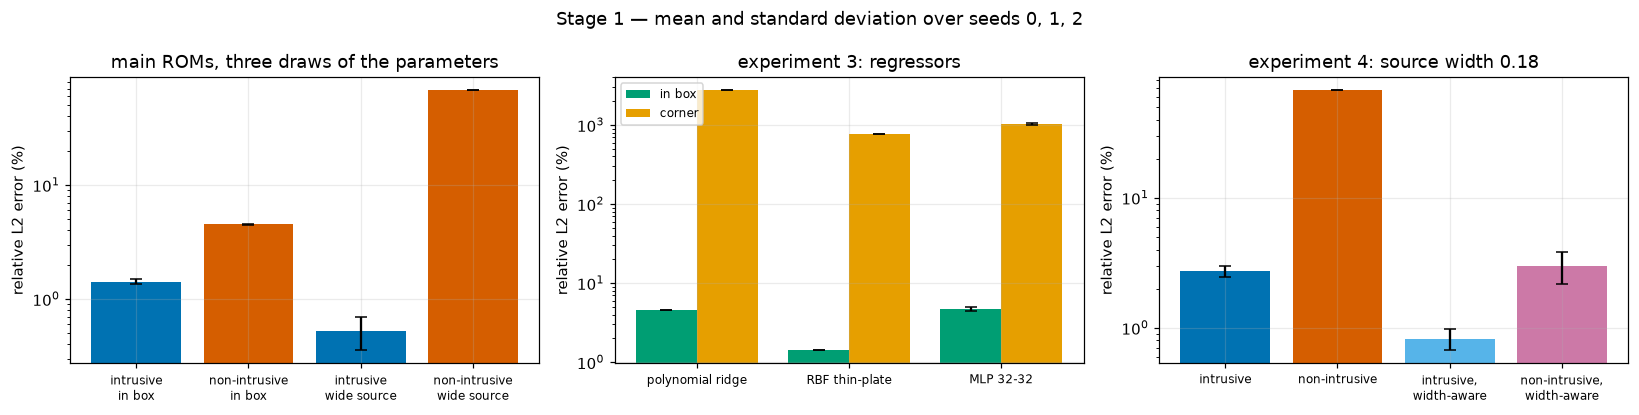

Result (three seeds): reconstruction_rank15: 1.06 ± 0.18 %; intrusive_in_box: 1.42 ± 0.08 %; nonintrusive_in_box: 4.52 ± 0.04 %; intrusive_centre: 1.04 ± 0.14 %; nonintrusive_centre: 4.57 ± 0.54 %; intrusive_corner: 75.91 ± 1.21 %; nonintrusive_corner: 2696.42 ± 173.15 %; knee_intrusive: 47.62 ± 4.12 %; knee_nonintrusive: 23.81 ± 10.91 %; intrusive_wide_source: 0.53 ± 0.17 %; nonintrusive_wide_source: 68.12 ± 0.03 %


In [41]:
agg = lambda d, by, cols: d.groupby(by, sort=False)[cols].agg(["mean", "std"])
s_main = seeds_main.drop(columns="seed").agg(["mean", "std"]).T; s_main.to_csv(ex_dir / "seeds_main_summary.csv")
s2 = agg(ex2_s, "box", ["knee_intrusive", "knee_nonintrusive", "corner_err_intrusive", "corner_err_nonintrusive"])
s3 = agg(ex3_s, "regressor", ["in_box_error", "corner_error", "knee"])
s4 = agg(ex4_s, "test_width", ["base_intrusive", "base_nonintrusive", "width_aware_intrusive", "width_aware_nonintrusive"])
for n_, d_ in (("exp2", s2), ("exp3", s3), ("exp4", s4)):
    d_.columns = [f"{a}_{b}" for a, b in d_.columns]; d_.to_csv(ex_dir / f"seeds_{n_}_summary.csv")
print(s_main.round(4).to_string()); print(s2.round(4).to_string()); print(s3.round(4).to_string()); print(s4.round(4).to_string())
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
k_ = ["intrusive_in_box", "nonintrusive_in_box", "intrusive_wide_source", "nonintrusive_wide_source"]
ax[0].bar(range(4), [100 * s_main.loc[c, "mean"] for c in k_], yerr=[100 * s_main.loc[c, "std"] for c in k_], color=[CB[0], CB[3], CB[0], CB[3]], capsize=4)
ax[0].set_xticks(range(4), ["intrusive\nin box", "non-intrusive\nin box", "intrusive\nwide source", "non-intrusive\nwide source"], fontsize=8); ax[0].set_ylabel("relative L2 error (%)"); ax[0].set_yscale("log")
ax[0].set_title("main ROMs, three draws of the parameters")
x3 = np.arange(len(s3)); ax[1].bar(x3 - 0.2, 100 * s3.in_box_error_mean, 0.4, yerr=100 * s3.in_box_error_std, capsize=4, color=CB[2], label="in box")
ax[1].bar(x3 + 0.2, 100 * s3.corner_error_mean, 0.4, yerr=100 * s3.corner_error_std, capsize=4, color=CB[1], label="corner")
ax[1].set_xticks(x3, s3.index, fontsize=8); ax[1].set_yscale("log"); ax[1].set_ylabel("relative L2 error (%)"); ax[1].legend(fontsize=8); ax[1].set_title("experiment 3: regressors")
x4 = np.arange(4); w18 = s4.loc[0.18]
ax[2].bar(x4, [100 * w18[f"{c}_mean"] for c in ("base_intrusive", "base_nonintrusive", "width_aware_intrusive", "width_aware_nonintrusive")],
          yerr=[100 * w18[f"{c}_std"] for c in ("base_intrusive", "base_nonintrusive", "width_aware_intrusive", "width_aware_nonintrusive")], capsize=4, color=[CB[0], CB[3], CB[5], CB[4]])
ax[2].set_xticks(x4, ["intrusive", "non-intrusive", "intrusive,\nwidth-aware", "non-intrusive,\nwidth-aware"], fontsize=8); ax[2].set_yscale("log"); ax[2].set_ylabel("relative L2 error (%)")
ax[2].set_title("experiment 4: source width 0.18")
fig.suptitle("Stage 1 — mean and standard deviation over seeds 0, 1, 2"); plt.tight_layout(); plt.savefig(ex_dir / "seeds_summary.png", dpi=100); plt.show()
print("Result (three seeds): " + "; ".join(f"{c}: {100*s_main.loc[c,'mean']:.2f} ± {100*s_main.loc[c,'std']:.2f} %" for c in s_main.index))

# Animation — the reduced model stepping beside the full one
The notebook trains no network, so the animation follows the method as it runs: one fixed case, frames recorded during the run, the final frame saved, then the video rendered. The fixed case is the first of the 40 in-box test parameters, `test_mus[0]`, the case shown in Section 3. I step the full-order model and the rank-15 intrusive ROM through the 300 backward-Euler steps from T = 0 and record, every 10 steps, the two fields, their absolute difference and the relative L2 error so far. The video and its last frame go to the animations folder (`01_stepping_dashboard.mp4`, `01_final_frame.png`).

In [42]:
import pickle
from matplotlib.animation import FuncAnimation, FFMpegWriter
import imageio_ffmpeg
plt.rcParams["animation.ffmpeg_path"] = imageio_ffmpeg.get_ffmpeg_exe()
anim_dir = ANIM_DIR; anim_dir.mkdir(exist_ok=True)
mu_a = test_mus[0]; forcing_full = p.dt * p.source_term(mu_a); forcing_red = p.dt * (Phi.T @ p.source_term(mu_a)); A_inv_r = np.linalg.inv(A_r)
T_f, a_r, snaps = np.zeros(p.n_dof), np.zeros(RANK), []
for step in range(1, p.n_steps + 1):
    T_f = p.system_lu.solve(T_f + forcing_full); a_r = A_inv_r @ (a_r + forcing_red)
    if step % 10 == 0 or step == 1:
        T_r = Phi @ a_r; snaps.append(dict(step=step, fom=T_f.copy(), rom=T_r, rel=float(np.linalg.norm(T_f - T_r) / np.linalg.norm(T_f))))
pickle.dump(snaps, open(anim_dir / f"{ANIM_PREFIX}snapshots.pkl", "wb"))
print(f"{len(snaps)} snapshots; final relative error {snaps[-1]['rel']:.4f} (the Section 3 case: {ex_rel(fom_refs[0], rom(test_mus[0])):.4f})")
vmax_a = max(s['fom'].max() for s in snaps)
fig, axs = plt.subplots(1, 4, figsize=(17, 3.9))
def anim_draw(k):
    s_ = snaps[k]
    for a in axs: a.clear()
    for a, F_, ttl, cm, lo, hi in ((axs[0], s_["fom"], "full-order model", "inferno", 0, vmax_a), (axs[1], s_["rom"], f"intrusive ROM, r = {RANK}", "inferno", 0, vmax_a),
                                   (axs[2], np.abs(s_["rom"] - s_["fom"]), "|difference|", "viridis", 0, None)):
        a.imshow(as_grid(p, F_), extent=[0, 1, 0, 1], origin="lower", aspect="auto", cmap=cm, vmin=lo, vmax=hi); a.set_title(ttl); a.grid(False)
    axs[3].semilogy([x["step"] for x in snaps[:k + 1]], [x["rel"] for x in snaps[:k + 1]], "o-", ms=3, color=CB[0])
    axs[3].set_xlim(0, p.n_steps); axs[3].set_ylim(min(x["rel"] for x in snaps) * 0.5, max(x["rel"] for x in snaps) * 2)
    axs[3].set_xlabel("time step"); axs[3].set_ylabel("relative L2 error"); axs[3].set_title("ROM error so far")
    fig.suptitle(f"Stage 1 — backward-Euler steps of the full and the reduced model, mu = ({mu_a[0]:.3f}, {mu_a[1]:.3f}), step {s_['step']}"); fig.tight_layout()
anim_draw(len(snaps) - 1); fig.savefig(anim_dir / f"{ANIM_PREFIX}final_frame.png", dpi=100)
FuncAnimation(fig, anim_draw, frames=len(snaps)).save(anim_dir / f"{ANIM_PREFIX}stepping_dashboard.mp4", writer=FFMpegWriter(fps=6, bitrate=1600), dpi=90)
plt.close(fig); print(f"Animation: {len(snaps)} frames written")

31 snapshots; final relative error 0.0138 (the Section 3 case: 0.0138)


Animation: 31 frames written


**What the animation shows.** Left to right: the full-order temperature, the rank-15 intrusive ROM's temperature, their absolute difference, all at the same time step, and the relative error of the ROM up to that step. The fields grow from zero towards the steady state; the ROM error is largest at the very first steps, when the field is a thin spike the 15 smooth modes cannot hold, and falls as the field spreads into shapes the snapshot basis was built from.